<h1><center>Генеративно состязательные сети</h1></center>

<h2>Загрузка данных

In [1]:
import torch
import torch.nn as nn
import math
import matplotlib.pyplot as plt
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader

In [2]:
torch.manual_seed(3)

In [3]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((.5), (.5))
])

train_dataset = torchvision.datasets.MNIST(root='./SimpleNN', train=True,
                                           download=True, transform=transform)

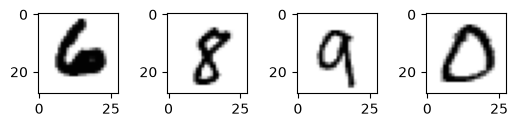

In [19]:
BATCH_SIZE = 32
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE,
                          shuffle=True)

real_sample, mnist_labels = next(iter(train_loader))
for i in range(4):
    ax = plt.subplot(4, 4, i + 1)
    plt.imshow(real_sample[i].reshape(28, 28), cmap='gray_r')

<h2>Архитектура GAN

In [20]:
class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.model = nn.Sequential(
            nn.Linear(784, 1024),
            nn.ReLU(),
            nn.Dropout(p=.3),
            nn.Linear(1024, 512),
            nn.ReLU(),
            nn.Dropout(p=.3),
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Dropout(p=.3),
            nn.Linear(256, 1),
            nn.Sigmoid()
        )
    
    def forward(self, x):
        x = x.view(x.size(0), 784)
        output = self.model(x)
        return output

In [21]:
class Generetor(nn.Module):
    def __init__(self):
        super().__init__()
        self.model = nn.Sequential(
            nn.Linear(100, 256),
            nn.ReLU(),
            nn.Linear(256, 512),
            nn.ReLU(),
            nn.Linear(512, 1024),
            nn.ReLU(),
            nn.Linear(1024, 784),
            nn.Tanh()
        )
    
    def forward(self, x):
        output = self.model(x)
        output = output.view(x.size(0), 1, 28, 28)
        return output

In [22]:
device = 'cuda:0' if torch.cuda.is_available() else 'cpu'
device

'cuda:0'

In [23]:
gen = Generetor().to(device)
disc = Discriminator().to(device)

In [24]:
EPOCHS = 25
lr = .0002
criterion = nn.BCELoss()
optimizer_G = torch.optim.Adam(gen.parameters(), lr=lr)
opitimizer_D = torch.optim.Adam(disc.parameters(), lr=lr)

In [25]:
from tqdm.notebook import tqdm


for epoch in tqdm(range(EPOCHS)):
    loss_G_stat = 0.0
    loss_D_stat = 0.0
    for n, (real_sample, mnist_labels) in enumerate(tqdm(train_loader)):
        real_sample, mnist_labels = real_sample.to(device), mnist_labels.to(device)
        real_sample_labels = torch.ones((BATCH_SIZE, 1)).to(device)
        noise_samples = torch.randn((BATCH_SIZE, 100)).to(device)
        generated_samples = gen(noise_samples)
        generated_samples_labels = torch.zeros((BATCH_SIZE, 1)).to(device)
        all_samples = torch.cat((real_sample, generated_samples)).to(device)
        all_samples_labels = torch.cat((real_sample_labels, generated_samples_labels)).to(device)

        disc.zero_grad()
        output_D = disc(all_samples)
        loss_D = criterion(output_D, all_samples_labels)
        loss_D_stat += loss_D.item()
        loss_D.backward()
        opitimizer_D.step()

        gen.zero_grad()
        generated_samples = gen(noise_samples)
        output_D_G = disc(generated_samples)

        loss_D_G = criterion(output_D_G, real_sample_labels)
        loss_G_stat += loss_D_G.item()
        loss_D_G.backward()
        optimizer_G.step()

    print(f'Loss G: {loss_G_stat / len(train_loader)}, Loss D: {loss_D_stat / len(train_loader)}')

  0%|          | 0/25 [00:00<?, ?it/s]

  0%|          | 0/1875 [00:00<?, ?it/s]

Loss G: 3.8931294583797453, Loss D: 0.19182472528560707


  0%|          | 0/1875 [00:00<?, ?it/s]

Loss G: 3.856948000208537, Loss D: 0.11490471047870815


...

Loss G: 0.8993830491065979, Loss D: 0.6264417489528656


  0%|          | 0/1875 [00:00<?, ?it/s]

Loss G: 0.8982659229914347, Loss D: 0.6277223779678345


  0%|          | 0/1875 [00:00<?, ?it/s]

Loss G: 0.8957274991989136, Loss D: 0.628960462697347


In [26]:
EPOCHS = 100

for epoch in tqdm(range(EPOCHS)):
    if epoch % 10 == 0:
        torch.save(gen.state_dict(), f'D:/MIREA/DPO/Learning/Practic2_12/generator_weights_{epoch}.pt')
        torch.save(disc.state_dict(), f'D:/MIREA/DPO/Learning/Practic2_12/discriminator_weights_{epoch}.pt')
    for n, (real_sample, mnist_labels) in enumerate(tqdm(train_loader)):
        real_sample, mnist_labels = real_sample.to(device), mnist_labels.to(device)
        real_sample_labels = torch.ones((BATCH_SIZE, 1)).to(device)
        noise_samples = torch.randn((BATCH_SIZE, 100)).to(device)
        generated_samples = gen(noise_samples)
        generated_samples_labels = torch.zeros((BATCH_SIZE, 1)).to(device)
        all_samples = torch.cat((real_sample, generated_samples)).to(device)
        all_samples_labels = torch.cat((real_sample_labels, generated_samples_labels)).to(device)

        disc.zero_grad()
        output_D = disc(all_samples)
        loss_D = criterion(output_D, all_samples_labels)
        loss_D_stat += loss_D.item()
        loss_D.backward()
        opitimizer_D.step()

        gen.zero_grad()
        generated_samples = gen(noise_samples)
        output_D_G = disc(generated_samples)

        loss_D_G = criterion(output_D_G, real_sample_labels)
        loss_G_stat += loss_D_G.item()
        loss_D_G.backward()
        optimizer_G.step()

    print(f'Loss G: {loss_G_stat / len(train_loader)}, Loss D: {loss_D_stat / len(train_loader)}')

  0%|          | 0/100 [00:00<?, ?it/s]

  0%|          | 0/1875 [00:00<?, ?it/s]

Loss G: 1.795643724568685, Loss D: 1.2558882415771484


  0%|          | 0/1875 [00:00<?, ?it/s]

Loss G: 2.679668396695455, Loss D: 1.8884700635910034


...

Loss G: 86.25956533823013, Loss D: 62.88793372748693


  0%|          | 0/1875 [00:00<?, ?it/s]

Loss G: 87.13798654356003, Loss D: 63.51978781973521


  0%|          | 0/1875 [00:00<?, ?it/s]

Loss G: 88.01161155993144, Loss D: 64.1539821413517


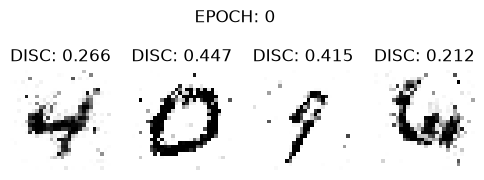

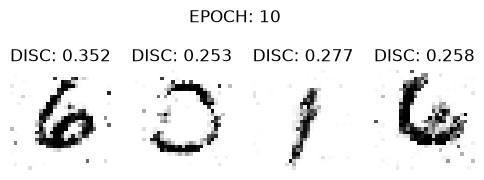

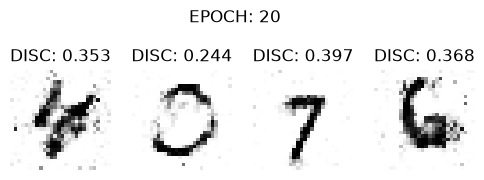

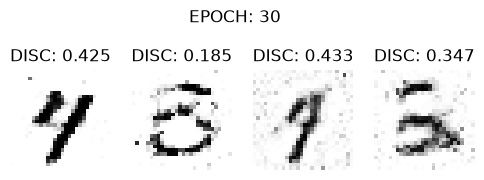

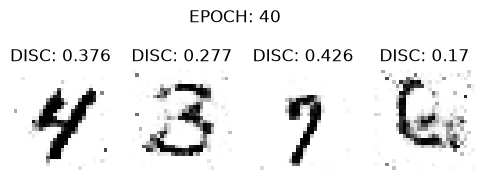

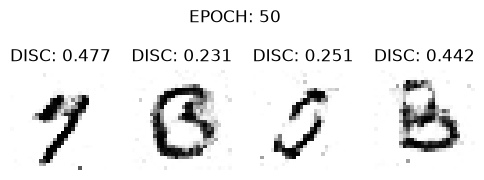

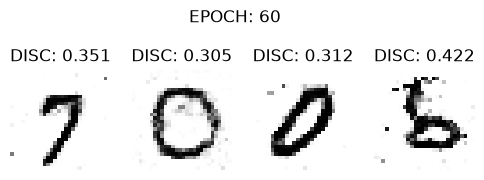

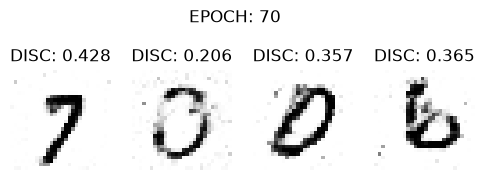

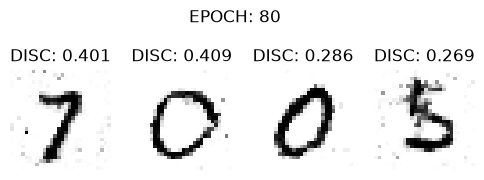

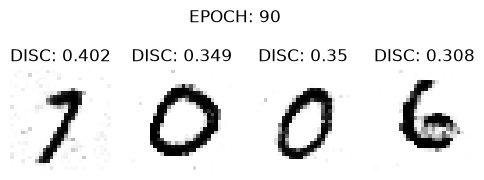

In [37]:
noise_samples = torch.randn((BATCH_SIZE, 100)).cpu()

for epoch in range(10):
    loaded_gen = Generetor().cpu()
    loaded_disc = Discriminator().cpu()

    weights_gen = torch.load(f'D:/MIREA/DPO/Learning/Practic2_12/generator_weights_{epoch * 10}.pt')
    weights_disc = torch.load(f'D:/MIREA/DPO/Learning/Practic2_12/discriminator_weights_{epoch * 10}.pt')

    loaded_gen.load_state_dict(weights_gen)
    loaded_disc.load_state_dict(weights_disc)

    loaded_gen.eval()
    loaded_disc.eval()

    with torch.no_grad():
        generated_samples = loaded_gen(noise_samples)
        disc_output = loaded_disc(generated_samples)
    
    generated_samples = generated_samples.detach()

    plt.figure(figsize=(6, 6))
    for i in range(4):
        ax = plt.subplot(4, 4, i + 1)
        score = disc_output[i].item()
        ax.set_title(f'DISC: {score:.3}')
        plt.imshow(generated_samples[i].reshape(28, 28), cmap='gray_r')
        plt.axis('off')

    plt.suptitle(f'EPOCH: {epoch * 10}')
    plt.show()

In [41]:
print(sum(p.numel() for p in gen.parameters()) + sum(p.numel() for p in disc.parameters()))

2946577


<h2>Состязательные атаки</h2>

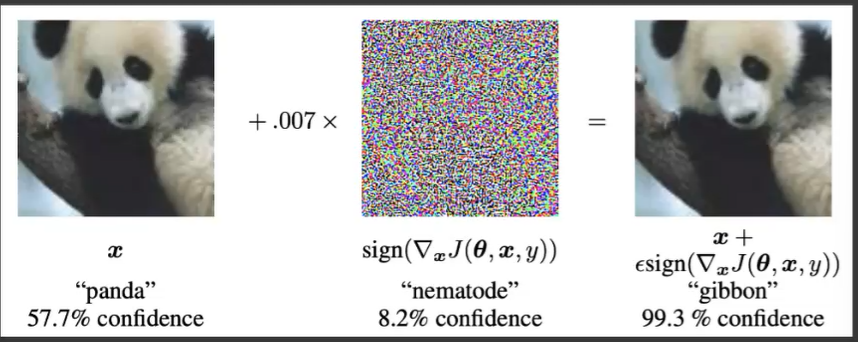

In [43]:
!pip install git+https://github.com/cleverhans-lab/cleverhans.git

  Cloning https://github.com/cleverhans-lab/cleverhans.git to C:\Users\nuyki\AppData\Local\Temp\pip-req-build-xob0i8go
  Resolved https://github.com/cleverhans-lab/cleverhans.git to commit 574efc1d2f5c7e102c78cf0e937654e847267522
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
   ---------------------------------------- 0.0/7.0 MB ? eta -:--:--
   --------- ------------------------------ 1.6/7.0 MB 8.4 MB/s eta 0:00:01
   ------------------- -------------------- 3.4/7.0 MB 8.8 MB/s eta 0:00:01
   ---------------------------- ----------- 5.0/7.0 MB 8.9 MB/s eta 0:00:01
   ------------------------------------- -- 6.6/7.0 MB 8.1 MB/s eta 0:00:01
   ---------------------------------------  6.8/7.0 MB 7.8 MB/s eta

  Running command git clone --filter=blob:none --quiet https://github.com/cleverhans-lab/cleverhans.git 'C:\Users\nuyki\AppData\Local\Temp\pip-req-build-xob0i8go'


In [60]:
model = torch.hub.load('pytorch/vision:v0.10.0', 'vgg11', pretrained=True)
model.eval()

Using cache found in C:\Users\nuyki/.cache\torch\hub\pytorch_vision_v0.10.0
d:\MIREA\DPO\.venv3_11_8\Lib\site-packages\torchvision\models\_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
d:\MIREA\DPO\.venv3_11_8\Lib\site-packages\torchvision\models\_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=VGG11_Weights.IMAGENET1K_V1`. You can also use `weights=VGG11_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


VGG(
  (features): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU(inplace=True)
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU(inplace=True)
    (8): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): ReLU(inplace=True)
    (10): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (11): Conv2d(256, 512, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (12): ReLU(inplace=True)
    (13): Conv2d(512, 512, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (14): ReLU(inplace=True)
    (15): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
 

In [47]:
import urllib.request

url = 'https://raw.githubusercontent.com/pytorch/hub/master/imagenet_classes.txt'
output_path = 'imagenet_classes.txt'

urllib.request.urlretrieve(url, output_path)

('imagenet_classes.txt', <http.client.HTTPMessage at 0x24793a9b210>)

In [48]:
with open('imagenet_classes.txt', 'r') as f:
    categories = [s.strip() for s in f.readlines()]
categories

['tench',
 'goldfish',
 'great white shark',
 'tiger shark',
 'hammerhead',
 'electric ray',
 'stingray',
 'cock',
 'hen',
 'ostrich',
 'brambling',
 'goldfinch',
 'house finch',
 'junco',
 'indigo bunting',
 'robin',
 'bulbul',
 'jay',
 'magpie',
 'chickadee',
 'water ouzel',
 'kite',
 'bald eagle',
 'vulture',
 'great grey owl',
 'European fire salamander',
 'common newt',
 'eft',
 'spotted salamander',
 'axolotl',
 'bullfrog',
 'tree frog',
 'tailed frog',
 'loggerhead',
 'leatherback turtle',
 'mud turtle',
 'terrapin',
 'box turtle',
 'banded gecko',
 'common iguana',
 'American chameleon',
 'whiptail',
 'agama',
 'frilled lizard',
 'alligator lizard',
 'Gila monster',
 'green lizard',
 'African chameleon',
 'Komodo dragon',
 'African crocodile',
 'American alligator',
 'triceratops',
 'thunder snake',
 'ringneck snake',
 'hognose snake',
 'green snake',
 'king snake',
 'garter snake',
 'water snake',
 'vine snake',
 'night snake',
 'boa constrictor',
 'rock python',
 'Indian cobr

<h2>Атака на нейронную сеть

In [55]:
from PIL import Image


input_image = Image.open('cotik.jpg')

preprocess = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=[.485, .456, .406], std=[.229, .224, .225])
])

postprocess = transforms.Compose([
    transforms.Normalize(mean=[0.0, 0.0, 0.0], std=[1 / .229, 1 / .224, 1 / .225]),
    transforms.Normalize(mean=[-.486, -.456, -.406], std=[1., 1., 1.])
])

input_tensor = preprocess(input_image)
input_batch = input_tensor.unsqueeze(0)

In [62]:
if torch.cuda.is_available():
    input_batch = input_batch.to(device)
    model.to(device)

with torch.inference_mode():
    output = model(input_batch)

probs = torch.nn.functional.softmax(output[0], dim=0)

In [63]:
top_5_probs, top_5_catid = torch.topk(probs, 5)

for i in range(top_5_probs.size(0)):
    print(categories[top_5_catid[i]], top_5_probs[i].item())

Egyptian cat 0.7288488149642944
tabby 0.14387458562850952
tiger cat 0.09840444475412369
lynx 0.014122122898697853
swab 0.0025917685125023127


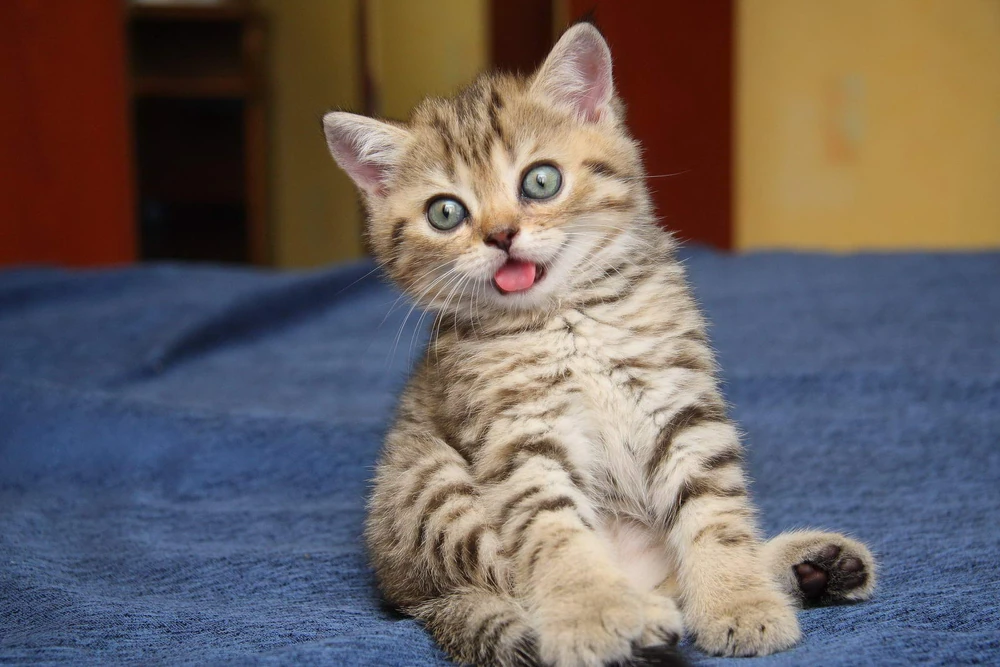

In [57]:
display(input_image)

In [64]:
from cleverhans.torch.attacks.fast_gradient_method import fast_gradient_method
import numpy as np


NUM_STEPS = 10
EPSILON = 1e-2
targeted = True

goal = 1
BATCH_SIZE = 1
target = goal * np.ones(shape=[BATCH_SIZE]).astype('long')
target = torch.tensor(target, dtype=torch.long)
real_im = input_batch

In [65]:
categories[goal]

'goldfish'

In [66]:
if torch.cuda.is_available():
    real_im = real_im.to(device)

preds = model(real_im)
preds = preds.cpu().detach()
preds = torch.nn.functional.softmax(preds[0], dim=0)
pred_prob, pred_catid = torch.topk(preds, 1)

print(categories[pred_catid], pred_prob.item())

Egyptian cat 0.7288488149642944


In [67]:
adv_im = real_im

if torch.cuda.is_available():
    target = target.to(device)

for i in tqdm(range(0, NUM_STEPS)):
    if targeted:
        adv_im = fast_gradient_method(model, adv_im,
                                      eps=EPSILON, targeted=True,
                                      y=target, norm=np.inf)
    else:
        adv_im = fast_gradient_method(model, adv_im,
                                      eps=EPSILON, targeted=False,
                                      norm=np.inf)

  0%|          | 0/10 [00:00<?, ?it/s]

In [68]:
preds_adv = model(adv_im)
preds_adv = preds_adv.cpu().detach()
preds_adv = torch.nn.functional.softmax(preds_adv[0], dim=0)
preds_adv_prod, preds_adv_catid = torch.topk(preds_adv, 1)
print(preds_adv_catid.item(), categories[preds_adv_catid], preds_adv_prod.item())

1 goldfish 0.9943453669548035


In [73]:
def show_adv(tensor_clean, tensor_adv, class_clean, class_adv, class_real,
             class_target, postprocess):
    plt.rcParams['figure.figsize'] = [14.00, 7.00]
    plt.rcParams['figure.autolayout'] = True

    plt.subplot(131)

    img_clean = postprocess(tensor_clean)
    img_clean = img_clean.cpu().detach().numpy()
    img_clean = np.moveaxis(img_clean, 1, -1)[0]
    plt.imshow(img_clean)

    title = [class_real, class_clean]
    plt.title(title)
    plt.axis('off')

    plt.subplot(132)

    img_adv = postprocess(tensor_adv)
    img_adv = img_adv.cpu().detach().numpy()
    img_adv = np.moveaxis(img_adv, 1, -1)[0]
    plt.imshow(img_adv)

    title = [class_target, class_adv]
    plt.title(title)
    plt.axis('off')

    plt.subplot(133)

    plt.imshow(100 * (img_clean - img_adv))
    title = ['img_clean - img.adv']
    plt.title(title)
    plt.axis('off')

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.01015684..0.96833956].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-2.2900014..2.2900014].


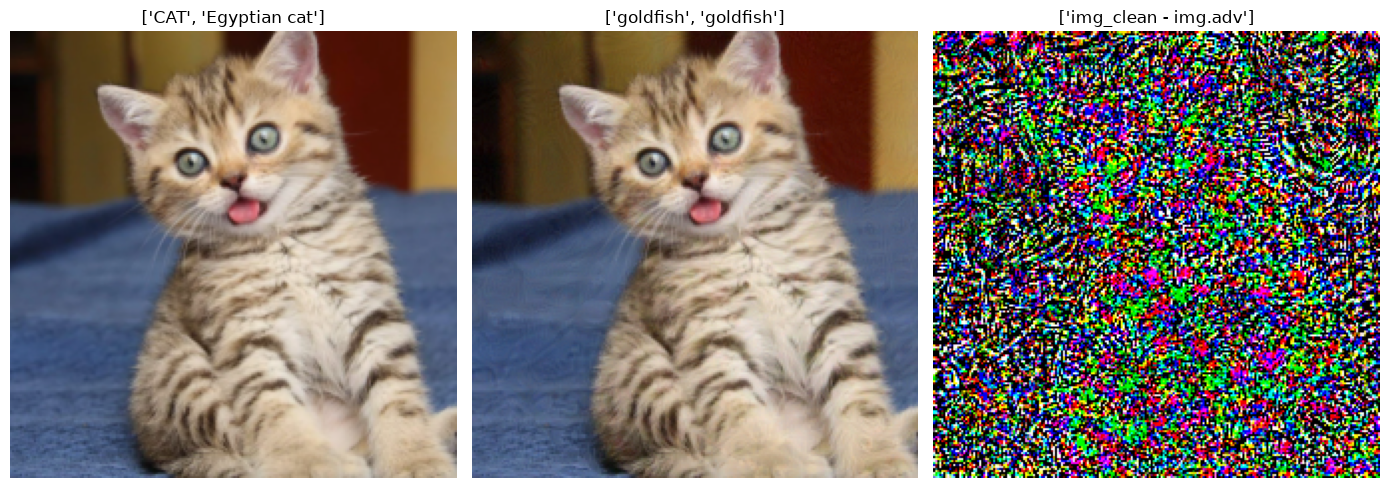

In [74]:
class_clean = categories[pred_catid]
class_adv = categories[preds_adv_catid]
class_real = 'CAT'
class_target = categories[goal]
show_adv(real_im, adv_im, class_clean, class_adv, class_real, class_target,
         postprocess=postprocess)